# Idorsia rNPV, working notebook

*A risk adjusted NPV of Idorsia's pipeline, product by product.*

This notebook is the reproducible workbook behind the site's
[Results](../results.html) page. Every input is either sourced to a
public document or explicitly flagged as an assumption in
[`src/assumptions.py`](https://github.com/DimitriPr/rnpv-idorsia-valuation/blob/main/src/assumptions.py). The narrative
version of the conclusions lives in `results.qmd`; this notebook is the
audit trail.

**Structure**

1. Idorsia at a glance, market data and 2025 financials
2. The structural puzzle, parent Ltd vs Idorsia Investments SARL
3. Assumptions, pipeline, PoS benchmarks, discount rate
4. Revenue projections
5. Product level rNPVs
6. Enterprise value bridge
7. Sensitivities
8. Scenarios, fair value vs market
9. Verdict and limitations

In [1]:
%matplotlib inline
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import assumptions as A
from src import rnpv
from src import sensitivity as S

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
FIG_DIR = ROOT / "outputs" / "figures"

## 1. Idorsia at a glance

Idorsia Ltd (SIX: IDIA) is a Swiss specialty biotech founded on the
scientific legacy of Actelion. It runs one commercial product
(**QUVIVIQ / daridorexant**, insomnia, approved US 2022, EU 2022) and
a clinical pipeline led by lucerastat (Phase 3, Fabry disease). A second
approved product, **TRYVIO / JERAYGO** (aprocitentan, resistant
hypertension), was **transferred in 2025 to a ring-fenced subsidiary**
(Idorsia Investments SARL) to service the restructured notes (A1 CHF 121 M
+ A2 CHF 260 M + B CHF 394 M = CHF 775 M at 30 Jun 2026). We come back to
the structural puzzle in §2.

Market and share data at the valuation date (30 Jun 2026, mid-year):

In [2]:
snapshot = pd.DataFrame({
    "Metric": [
        "Share price, close 31/12/25",
        "Market cap 31/12/25",
        "Share price, latest",
        "Issued shares (30 Jun 2026, H1 2026 Report p.12)",
        "J&J mandatory conversion (15 Jun 2027)",
        "Warrants (strike CHF 1.49, expiry Jun 2027)",
        "Unvested free shares",
        "Diluted shares, valuation basis",
        "CB 2034 if-converted (strike CHF 6.00)",
        "Options (strike CHF 10.97, informational)",
        "Valuation date",
    ],
    "Value": [
        f"CHF {A.SHARE_PRICE_YE2025_CHF:.2f}",
        f"CHF {A.MARKET_CAP_YE2025_CHF_M:,.0f} M",
        f"CHF {A.SHARE_PRICE_CURRENT_CHF:.2f}  (as of {A.SHARE_PRICE_CURRENT_AS_OF}, {A.SHARE_PRICE_STATUS})",
        f"{A.SHARES_ISSUED_M:.1f} M",
        f"+ {A.SHARES_JJ_CONVERSION_M:.1f} M",
        f"+ {A.SHARES_WARRANTS_M:.2f} M (cash in CHF {A.SHARES_WARRANTS_CASH_IN_CHF_M:.1f} M)",
        f"+ {A.SHARES_UNVESTED_FREE_M:.1f} M",
        f"= {A.SHARES_ISSUED_M + A.SHARES_JJ_CONVERSION_M + A.SHARES_WARRANTS_M + A.SHARES_UNVESTED_FREE_M:.2f} M",
        f"+ {A.SHARES_CB_2034_IFCONVERTED_M:.2f} M (conditional on V/share > 6.00)",
        f"+ {A.SHARES_OPTIONS_M:.1f} M (excluded from valuation denominator)",
        A.VALUATION_DATE,
    ],
})
snapshot

,Metric,Value
0,"Share price, close 31/12/25",CHF 4.26
1,Market cap 31/12/25,"CHF 1,070 M"
2,"Share price, latest","CHF 4.16 (as of 2026-10-13, sourced)"
3,"Issued shares (30 Jun 2026, H1 2026 Report p.12)",263.1 M
4,J&J mandatory conversion (15 Jun 2027),+ 21.7 M
5,"Warrants (strike CHF 1.49, expiry Jun 2027)",+ 10.85 M (cash in CHF 16.2 M)
6,Unvested free shares,+ 9.5 M
7,"Diluted shares, valuation basis",= 305.15 M
8,CB 2034 if-converted (strike CHF 6.00),+ 2.72 M (conditional on V/share > 6.00)
9,"Options (strike CHF 10.97, informational)",+ 7.1 M (excluded from valuation denominator)


H1 2026 non-GAAP (H1 Report p.3, p.6): net revenue CHF 105 M (QUVIVIQ 97 M
+ contract revenue 8 M; TRYVIO sits inside the SARL at CHF 0.3 M), total
expenses CHF 160 M, operating result CHF -54 M. On an annualised H1 x 2
basis, total opex (CHF 320 M) sits below the full-year guidance ceiling
of CHF 330 M, so Idorsia is on track with its own guidance.

Full-year 2026 guidance: QUVIVIQ CHF 200 M, non-GAAP operating loss
CHF 120 M. 2025 non-GAAP (AR 2025): net revenue CHF 214 M, operating loss
CHF 100 M.

## 2. The structural puzzle, parent vs SARL

This is the single point on which naive valuations of Idorsia go wrong.

In May 2025 Idorsia transferred the rights to **aprocitentan (TRYVIO /
JERAYGO)**, **selatogrel** and **cenerimod** to a newly created
subsidiary, **Idorsia Investments SARL**. That SARL secures the Notes
A1 (CHF 121 M), A2 (CHF 260 M) and B (CHF 394 M) at 30 Jun 2026, total
CHF 775 M, maturing 2048/2050 and PIK (payment-in-kind). Rights revert
to the parent (Idorsia Ltd, SIX listed) *after* the SARL debt + interest
are fully repaid. The CHF 150 M SARL New Money Facility was repaid in
full on 25 Jun 2026 using proceeds from the new Pharmakon term loan at
op co; it is zero at the valuation date.

**Important nuance**: notes A1 / A2 carry a *limited and subordinated
guarantee from Idorsia Ltd* (H1 Report p.17, p.41). The phrase
"non-recourse to IDIA shareholders" is therefore inaccurate; the exact
exposure is deliberately conservative-ignored in the base case and
flagged in Limitations.

For an equity holder of IDIA, this means:

- **What the parent captures directly**: QUVIVIQ + the R&D pipeline
  (lucerastat, CCR6, CXCR7, CXCR3, C. diff vaccine).
- **What the parent captures conditionally**: the SARL residual once the
  ring-fenced debt is retired. Deep out of the money option, set to 0 in
  the base case, stressed to CHF 400-600 M in scenarios.
- **What the parent also pays** (new in v1.2, central line): a J&J
  residual royalty on net sales of all Idorsia products, 4 % of PoS-
  weighted aggregate sales until the CHF 272 M remaining cap is reached
  (H1 Report note 4, p.32).

The parent-attributable debt / cash bridge at 30 Jun 2026:

In [3]:
bs = pd.DataFrame({
    "Item": [
        "Group cash and equivalents (H1 p.22, upper bound)",
        "+ Warrant exercise cash (CHF 1.49 strike x 10.85 M)",
        "= Parent-attributable cash (used in bridge)",
        "Pharmakon term loan (drawn 26/06/2026, matures 2031)",
        "Convertible bonds CB 2034 + CB 2038",
        "Sale-and-leaseback debt",
        "Parent-attributable net cash (used in bridge)",
        "---",
        "SARL notes A1 + A2 + B (ring-fenced, limited guarantee)",
        "J&J convertible, settles in 21.7 M shares at CHF 11.48 (not debt)",
    ],
    "CHF M": [
        A.CASH_30JUN2026_CHF_M,
        A.SHARES_WARRANTS_CASH_IN_CHF_M,
        A.PARENT_ATTRIBUTABLE_CASH_CHF_M,
        -A.DEBT_PHARMAKON_LOAN_CHF_M,
        -A.DEBT_CONVERTIBLE_BONDS_CHF_M,
        -A.DEBT_SALE_LEASEBACK_CHF_M,
        A.parent_net_cash_chf_m(),
        None,
        -A.DEBT_NOTES_SARL_CHF_M,
        0.0,
    ],
})
bs

,Item,CHF M
0,"Group cash and equivalents (H1 p.22, upper bound)",88.70
1,+ Warrant exercise cash (CHF 1.49 strike x 10....,16.20
2,= Parent-attributable cash (used in bridge),104.90
3,"Pharmakon term loan (drawn 26/06/2026, matures...",-150.00
4,Convertible bonds CB 2034 + CB 2038,-49.30
5,Sale-and-leaseback debt,-162.00
6,Parent-attributable net cash (used in bridge),-256.40
7,---,NaN
8,"SARL notes A1 + A2 + B (ring-fenced, limited g...",-775.00
9,"J&J convertible, settles in 21.7 M shares at C...",0.00


The J&J convertible loan (CHF 250 M remaining after the 19 Jun 2026 tranche
conversion of CHF 85 M into 7.4 M IDIA shares), zero coupon, matures
15 Jun 2027. The remaining principal converts into 21.7 M IDIA shares
at CHF 11.48. The Pharmakon term loan covenant (H1 p.44) **forbids cash
repayment of a convertible loan**, so from the IDIA equity holder's
perspective the remaining principal is a *deterministic* share issuance
at maturity, not optional debt. The convertible contributes neither debt
to the parent bridge nor an if-converted test; the 21.7 M new shares
are already in the valuation denominator.

The *if-converted test* in the model therefore applies only to the
CB 2034 (CHF 16.5 M nominal, strike CHF 6.00, 2.72 M shares if converted).
CB 2038 (strike CHF 31.54) stays out of the money across all scenarios.

## 3. Assumptions

**Discount rate.** 12 % (biotech WACC range 11-13 %; stress at 10 %/14 %).

**PoS transitions**, BIO/Informa/QLS, "Clinical Development Success
Rates 2011-2020" (2021). Transitions and derived cumulative PoS:

In [4]:
trans = pd.DataFrame(
    [("Phase 1 -> Phase 2",  A.POS_TRANSITIONS["phase1_to_phase2"]),
     ("Phase 2 -> Phase 3",  A.POS_TRANSITIONS["phase2_to_phase3"]),
     ("Phase 3 -> NDA/BLA",  A.POS_TRANSITIONS["phase3_to_filing"]),
     ("NDA/BLA -> approval", A.POS_TRANSITIONS["filing_to_approval"])],
    columns=["Transition", "Probability"],
)
trans["Probability"] = trans["Probability"].map(lambda x: f"{x*100:.1f} %")
trans

,Transition,Probability
0,Phase 1 -> Phase 2,52.0 %
1,Phase 2 -> Phase 3,28.9 %
2,Phase 3 -> NDA/BLA,57.8 %
3,NDA/BLA -> approval,90.6 %


In [5]:
cum = pd.DataFrame(
    [(ph, A.cumulative_pos(ph)) for ph in ["phase1", "phase2", "phase3", "filing"]],
    columns=["From phase", "Cumulative PoS to approval"],
)
cum["Cumulative PoS to approval"] = cum["Cumulative PoS to approval"].map(lambda x: f"{x*100:.1f} %")
cum

,From phase,Cumulative PoS to approval
0,phase1,7.9 %
1,phase2,15.1 %
2,phase3,52.4 %
3,filing,90.6 %


**Pipeline**, six products; the three SARL assets (aprocitentan,
selatogrel, cenerimod) are excluded by design (see §2). Each product's
peak sales, ramp, patent expiry and operating margin are documented with
sources in `src/assumptions.py`.

In [6]:
def _phase_label(p):
    return p["phase"]

pipeline = pd.DataFrame([{
    "Product": p["name"],
    "Indication": p["indication"],
    "Phase": _phase_label(p),
    "PoS": p["pos"],
    "Launch": p["launch_year"],
    "Peak sales (CHF M)": p["peak_sales_chf_m"],
    "Ramp (yrs)": p["ramp_years"],
    "Patent expiry": p["patent_expiry"],
    "Op margin @ launch": p.get("op_margin_at_launch", p.get("op_margin", 0.0)),
    "Op margin @ peak":   p.get("op_margin_at_peak",   p.get("op_margin", 0.0)),
    "Included in base": p.get("include", True),
} for k, p in A.PRODUCTS.items()])
pipeline

,Product,Indication,Phase,PoS,Launch,Peak sales (CHF M),Ramp (yrs),Patent expiry,Op margin @ launch,Op margin @ peak,Included in base
0,QUVIVIQ (daridorexant),chronic insomnia,marketed,1.00,2022,600,8,2036,0.09,0.55,True
1,Lucerastat,"Fabry disease (oral, all mutations)",phase3,0.52,2031,400,4,2042,0.25,0.65,True
2,IDOR-1117-2520 (CCR6 antagonist),psoriasis (PoC) -> Th17 immune disorders,phase2,0.15,2033,300,5,2046,0.15,0.55,True
3,ACT-1004-1239 (CXCR7 antagonist),progressive multiple sclerosis,phase2,0.15,2034,400,6,2042,0.15,0.55,True
4,ACT-777991 (CXCR3 antagonist),vitiligo (PoC),phase2,0.15,2033,250,5,2041,0.15,0.55,True
5,IDOR-1134-2831 (C. diff synthetic glycan vaccine),C. difficile infection prevention,phase1,0.08,2035,200,5,2040,0.15,0.40,False


Three hypotheses carry most of the equity story and should be stressed
aggressively (§7 does that):

- **QUVIVIQ peak sales (CHF 600 M base)**. Belsomra plateaued at
  roughly USD 300 M globally; GlobalData projects the 7MM DORA class to
  reach USD 4.1 bn by 2032 (multi-drug). QUVIVIQ carries best-in-class
  daytime functioning. On 11 Aug 2026 the DEA proposed to **reclassify
  DORAs from Schedule IV to Schedule V** (not full descheduling); modest
  commercial accelerator, not a transformational catalyst. Base case
  CHF 600 M peak corresponds to a mid-range specialty biotech trajectory
  (the USD 1 bn global blockbuster threshold would be ~CHF 850 M of
  Idorsia-recognised net sales).
- **QUVIVIQ peak contribution margin (55 % base)**. 2026 anchor is 9 %
  sourced on H1 actuals ((97 - 19 - 69)/97, H1 p.3 / p.6); 2030 peak is
  an assumption built from COGS 12-20 % + Selling 25-30 % at steady
  state. Each +/-10 pp at peak is worth roughly CHF +/-0.80 / share.
- **Lucerastat peak sales (CHF 400 M base)**. Fabry market addressable
  ~USD 4 bn per Idorsia disclosure; comparables Fabrazyme peaked at
  ~USD 1 bn, Galafold at ~USD 450 M.

## 4. Revenue projections

Ramp -> plateau -> patent cliff, per product. Historical sales figures
(2023-2026) are hard anchored to the AR and to management guidance; the
model interpolates linearly to the peak year.

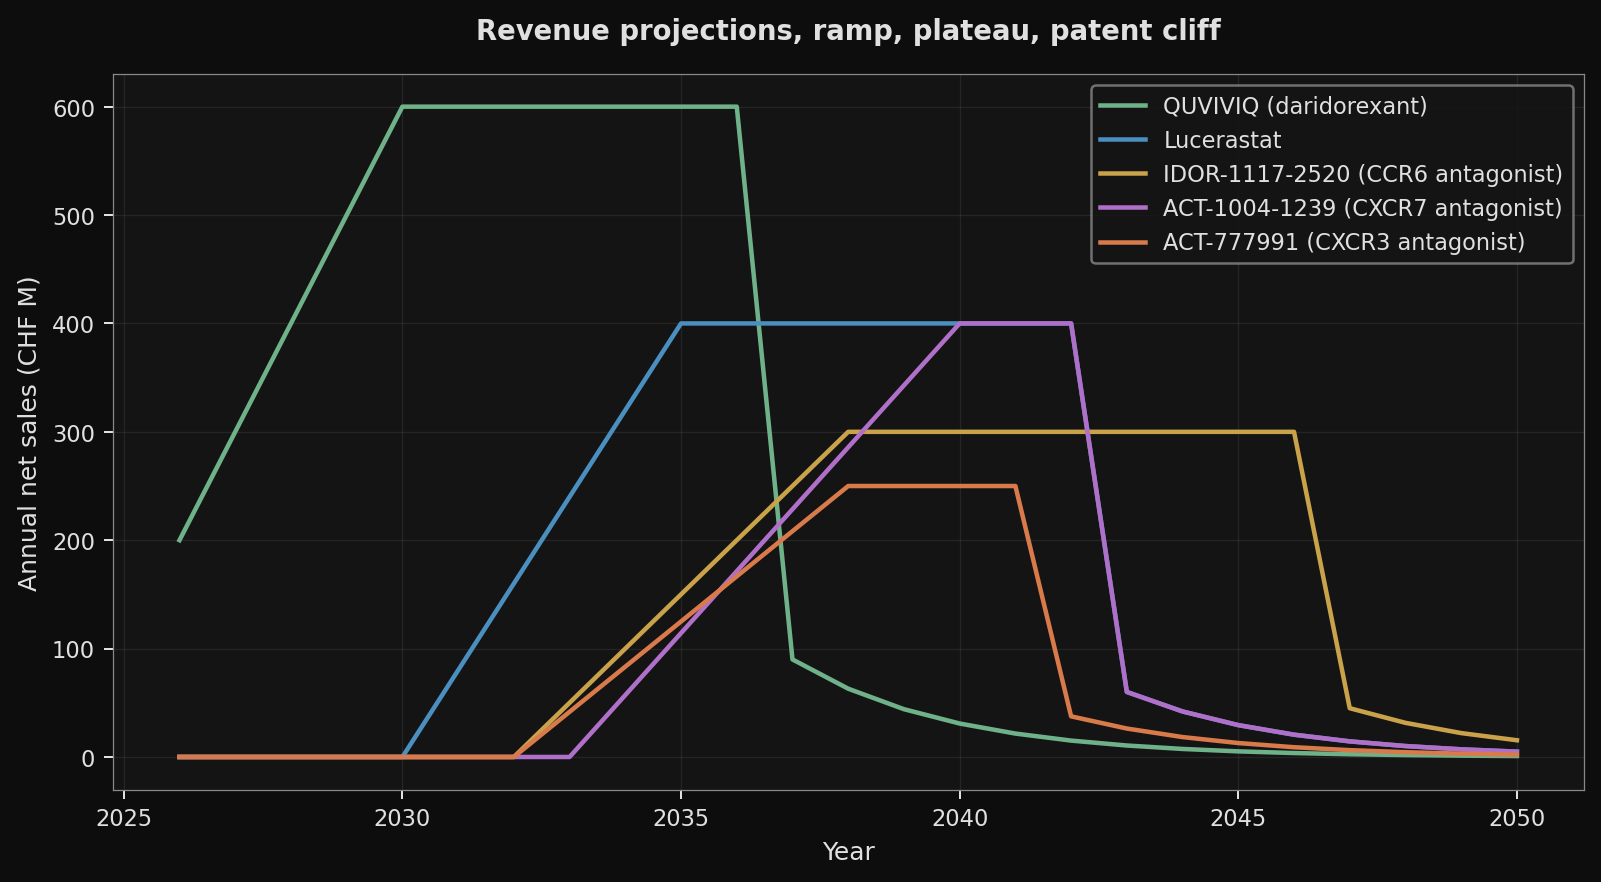

In [7]:
S.plot_revenue_curves()
display(Image(str(FIG_DIR / "revenue_curves.png"), width=900))

In [8]:
rev = rnpv.revenue_table()
rev.loc[[2026, 2028, 2030, 2032, 2035, 2037, 2040]].round(0)

,quviviq,lucerastat,ccr6_antagonist,cxcr7_antagonist,cxcr3_antagonist
2026,200.00,0.00,0.00,0.00,0.00
2028,400.00,0.00,0.00,0.00,0.00
2030,600.00,0.00,0.00,0.00,0.00
2032,600.00,160.00,0.00,0.00,0.00
2035,600.00,400.00,150.00,114.00,125.00
2037,90.00,400.00,250.00,229.00,208.00
2040,31.00,400.00,300.00,400.00,250.00


Notes on shape choices:

- QUVIVIQ ramp from CHF 200 M (2026 guidance) to CHF 600 M peak by 2030
  implies a linear 200 -> 300 -> 400 -> 500 -> 600 sequence (31.6 % CAGR
  from 2026 to 2030). Historical growth +97 % (2023->2024), +120 %
  (2024->2025), +49 % guided (2025->2026) is already *decelerating*; the
  implied 31.6 % CAGR continues that deceleration into 2026-2030.
  An earlier draft used a 6-year ramp (peak 2028) which implied 100 % +
  50 % YoY, defensible only on an aggressive combined bull case.
- Lucerastat starts in 2031 (post-2029 filing target) with a 4-year ramp,
  consistent with orphan drug launch dynamics.
- Patent cliffs use a -85 % drop the year after expiry, decaying 30 %/yr
  thereafter, standard rNPV convention.

## 5. Product level rNPVs

For each product: rNPV = PoS × PV(operating cash flow) - PV(remaining
development costs).

In [9]:
bridge = rnpv.value_per_share()
summary = rnpv.valuation_summary(bridge)
summary

,product,phase,pos,pv_operating_cf_chf_m,pv_dev_costs_chf_m,rnpv_chf_m
0,QUVIVIQ (daridorexant),marketed,1.00,"1,430.38",0.00,"1,430.38"
1,Lucerastat,phase3,0.52,696.10,80.35,284.17
2,IDOR-1117-2520 (CCR6 antagonist),phase2,0.15,358.84,81.38,-27.07
3,ACT-1004-1239 (CXCR7 antagonist),phase2,0.15,279.82,78.41,-36.06
4,ACT-777991 (CXCR3 antagonist),phase2,0.15,213.01,80.73,-48.50


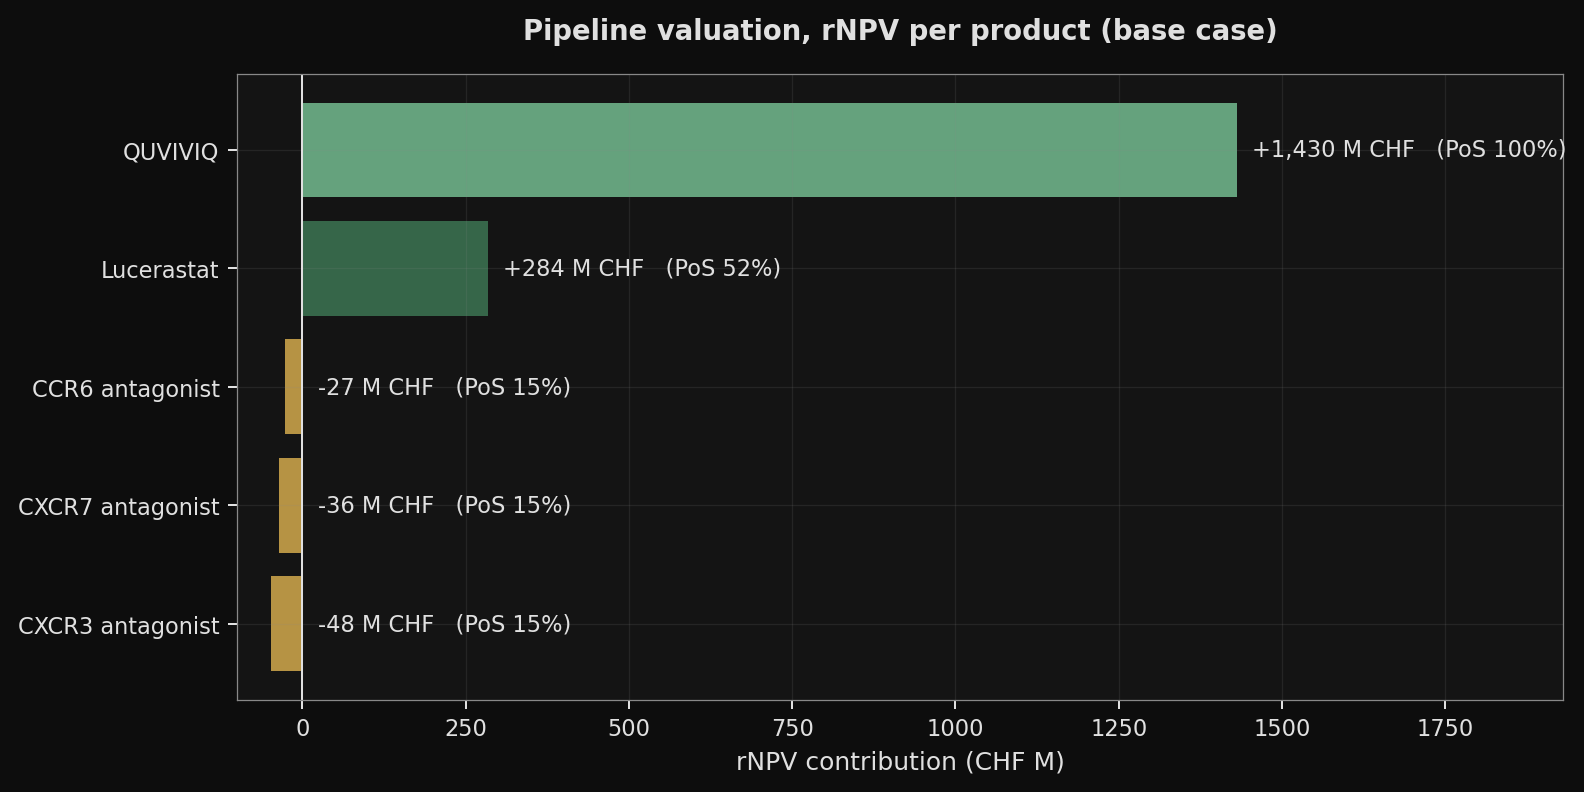

In [10]:
S.plot_pipeline_overview()
display(Image(str(FIG_DIR / "pipeline_overview.png"), width=900))

Read: **QUVIVIQ dominates** the base case. Lucerastat adds a positive
PoS-weighted contribution after development costs. The three early-stage
clinical candidates all print **negative rNPV** at current assumptions:
their Phase 2 cumulative LOA (15.1 % under BIO 2011-2020) applied to
CHF 250-400 M peak sales placeholders does not cover the phase-weighted
dev spend out to filing.

Interpretation: this is not a claim that these programmes should be
shelved. The peak sales placeholders (CHF 250-400 M for a first-in-class
oral in psoriasis / MS / vitiligo) are almost certainly conservative
relative to what those markets support. A positive PoC readout at Q4 2026
(CCR6) would justify reanchoring peak sales upward.

## 6. Enterprise value bridge, from cash to CHF / share

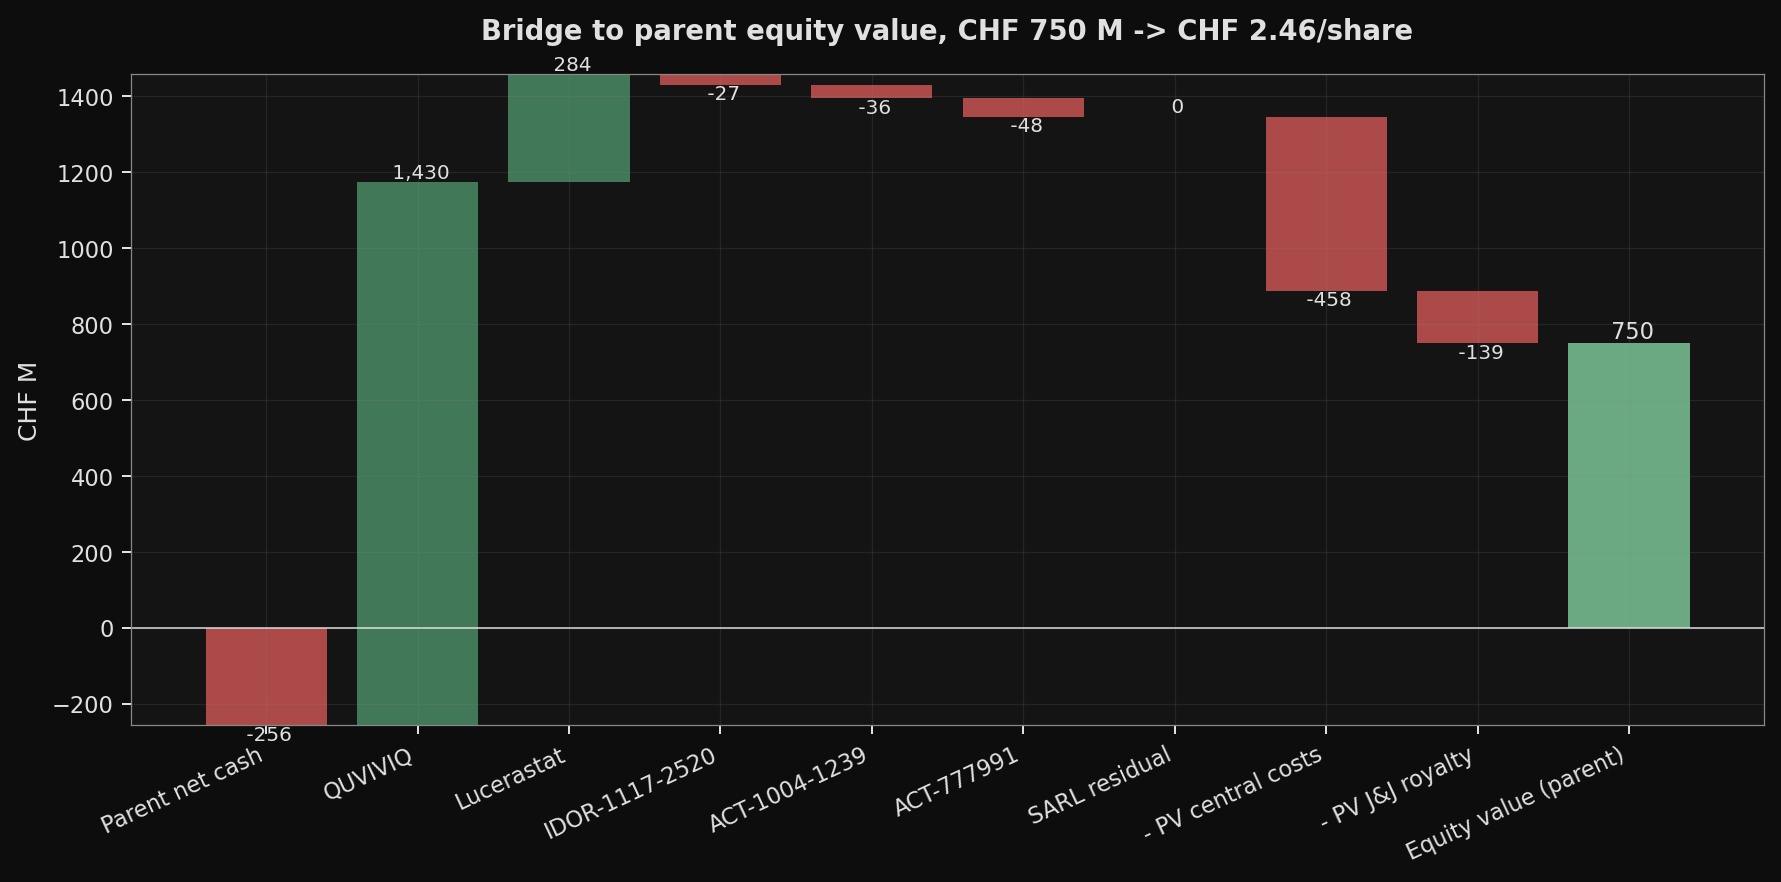

In [11]:
S.plot_waterfall()
display(Image(str(FIG_DIR / "waterfall_ev.png"), width=1000))

In [12]:
print(f"Sum of product rNPVs              : CHF {bridge['sum_rnpv_chf_m']:>+8,.0f} M")
print(f"+ Parent net cash                  : CHF {bridge['parent_net_cash_chf_m']:>+8,.0f} M")
print(f"+ SARL residual (base = 0)         : CHF {bridge['sarl_residual_chf_m']:>+8,.0f} M")
print(f"- PV central costs (G&A + upstream): CHF {-bridge['central_costs_pv_chf_m']:>+8,.0f} M")
print(f"- PV J&J residual royalty          : CHF {-bridge['jj_royalty_pv_chf_m']:>+8,.0f} M")
print(f"= Equity value (parent)            : CHF {bridge['equity_value_chf_m']:>+8,.0f} M")
print(f"Issued shares (30 Jun 2026)        :     {bridge['shares_issued_m']:>8,.1f} M")
print(f"Diluted shares, valuation basis    :     {bridge['shares_m']:>8,.2f} M")
print(f"= Fair value / share               : CHF {bridge['value_per_share_chf']:>+8,.2f}")
print(f"vs market price                    : CHF {bridge['market_price_chf']:>+8,.2f}")
print(f"Implied upside / (downside)        :     {bridge['upside_pct']:>+7,.1f} %")

Sum of product rNPVs              : CHF   +1,603 M
+ Parent net cash                  : CHF     -256 M
+ SARL residual (base = 0)         : CHF       +0 M
- PV central costs (G&A + upstream): CHF     -458 M
- PV J&J residual royalty          : CHF     -139 M
= Equity value (parent)            : CHF     +750 M
Issued shares (30 Jun 2026)        :        263.1 M
Diluted shares, valuation basis    :       305.15 M
= Fair value / share               : CHF    +2.46
vs market price                    : CHF    +4.16
Implied upside / (downside)        :       -40.9 %


**Composition of the diluted valuation basis** (305.15 M shares):

- Issued shares at 30 Jun 2026: 263.1 M (H1 Report p.12).
- J&J mandatory conversion (15 Jun 2027): +21.7 M at CHF 11.48.
- Warrants (strike CHF 1.49, expiry Jun 2027): +10.85 M; the exercise
  brings CHF 16.2 M of cash into the parent, already in the net-cash
  line.
- Unvested free shares: +9.5 M.
- (Conditional) CB 2034 if-converted (strike CHF 6.00): +2.72 M. Not
  in the denominator by default; the if-converted test adds them when
  V/share exceeds the strike.
- Options (7.1 M at CHF 10.97): excluded from the valuation denominator
  (strike well above the base case; informational only).

## 7. Sensitivities

### Heatmap, value/share vs QUVIVIQ peak sales × discount rate

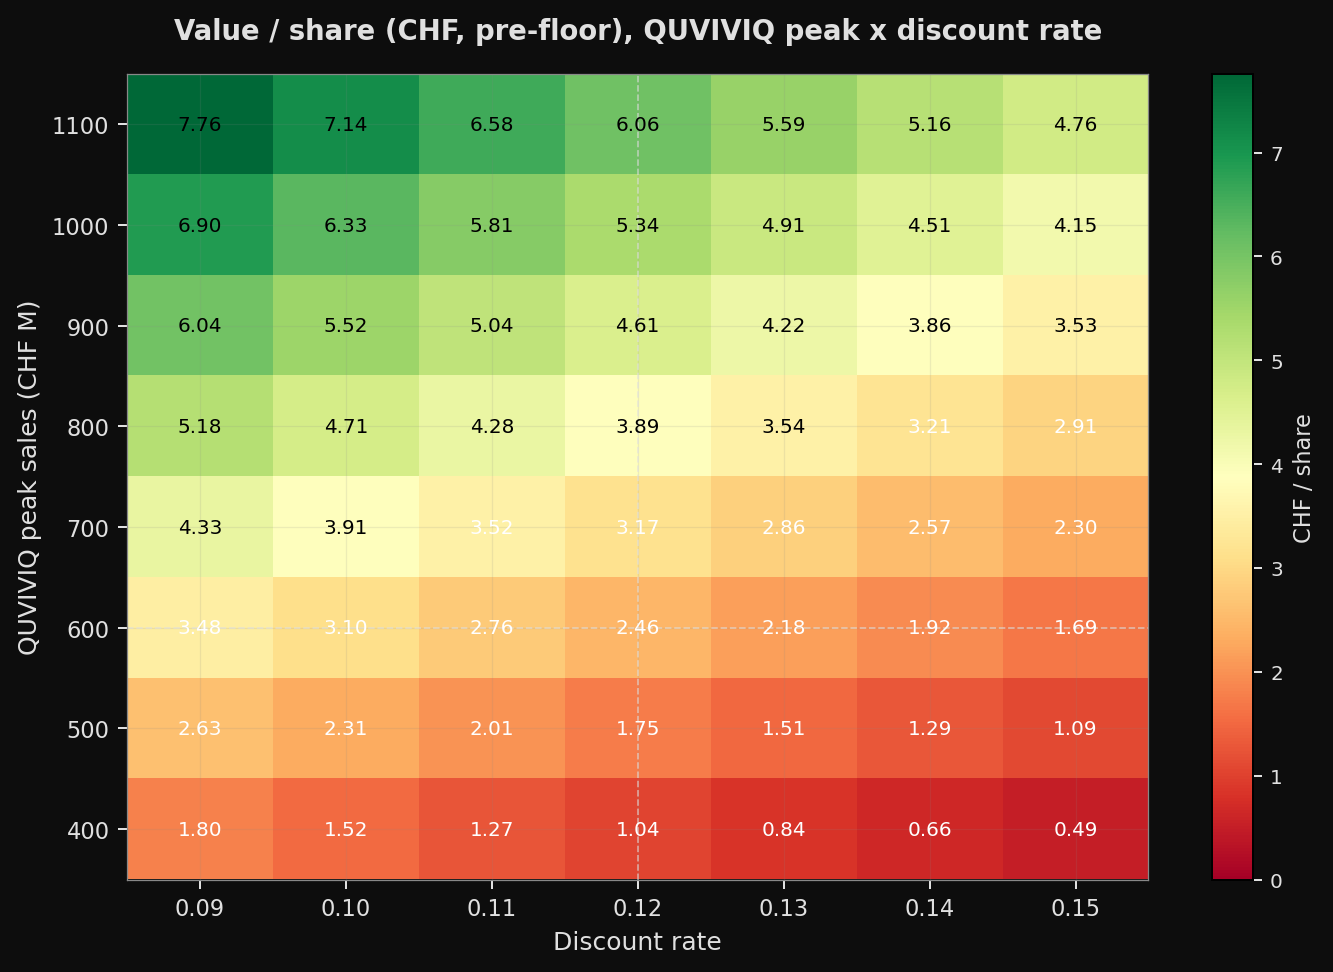

In [13]:
S.plot_heatmap(S.heatmap_rate_vs_quviviq_peak())
display(Image(str(FIG_DIR / "sensitivity_heatmap.png"), width=900))

To reach the current market price (shown on the figure, pulled from
`data/market.json`) requires QUVIVIQ peak sales well above the base-case
CHF 600 M *and* a discount rate at the low end of the biotech WACC range
(9-10 %), i.e. both variables at their optimistic ends simultaneously.
That is not implausible if the DEA Schedule V reclassification (proposed
11 Aug 2026, not full descheduling), label enhancement on daytime
functioning, and pediatric approval all land favourably; but each is a
separate probabilistic event.

### Tornado, variables ranked by impact on value/share

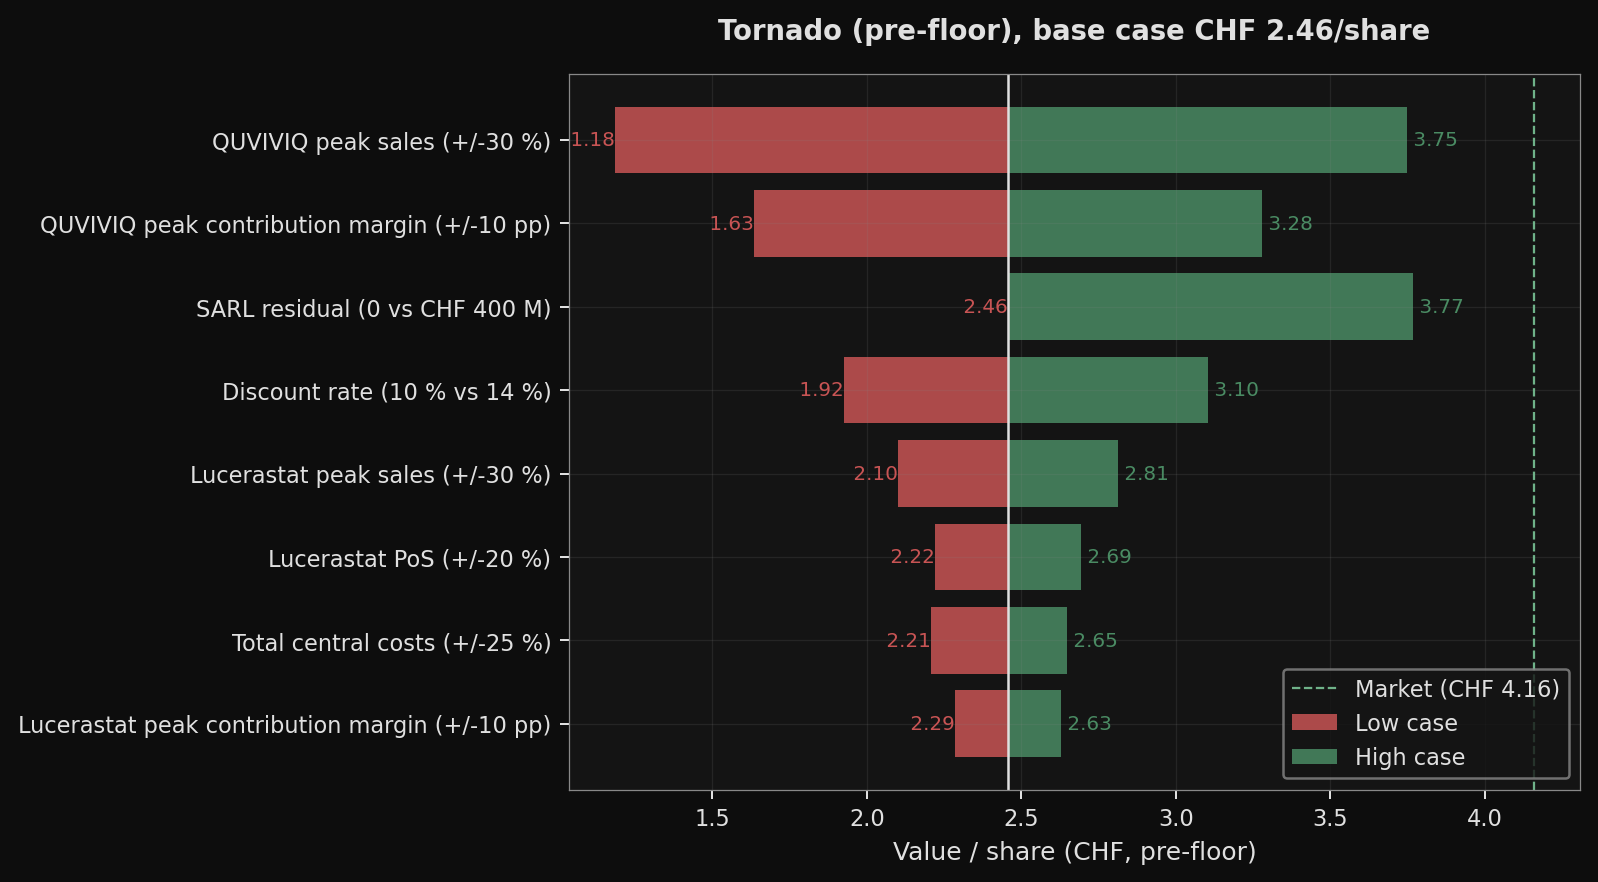

In [14]:
S.plot_tornado(S.tornado_data())
display(Image(str(FIG_DIR / "tornado.png"), width=900))

In v1.2 the dominant levers are **QUVIVIQ peak sales (+/-30 %)**, the
**SARL residual (0 vs CHF 400 M)**, and the **QUVIVIQ peak contribution
margin (+/-10 pp)**. Discount rate and lucerastat variables are mid-tier
levers. Total central costs (+/-25 %, G&A + upstream) and lucerastat PoS
(+/-20 %) are minor on their own.

A single lever at its stress case can approach but not fully reach the
current market price; the market embeds a joint positive bet.

## 8. Scenarios, fair value vs market

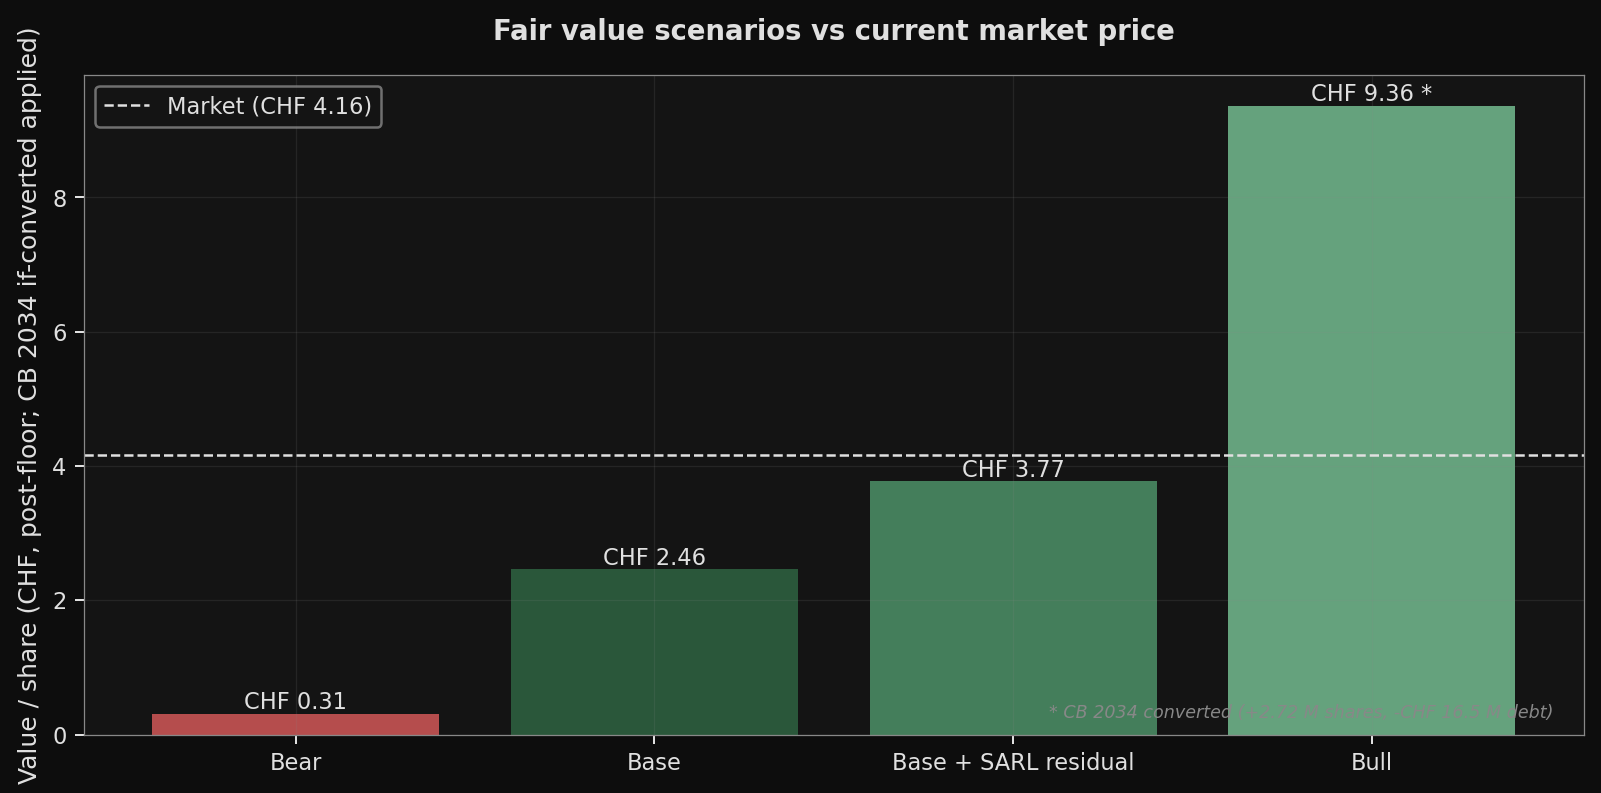

In [15]:
S.plot_fair_value_vs_market()
display(Image(str(FIG_DIR / "fair_value_vs_market.png"), width=900))

In [16]:
S.scenarios()

,scenario,value_per_share,value_per_share_pre_conversion,cb2034_converted,jj_converted
0,Bear,0.31,0.31,False,False
1,Base,2.46,2.46,False,False
2,Base + SARL residual,3.77,3.77,False,False
3,Bull,9.36,9.39,True,True


In [17]:
# Dynamic scenario commentary driven by the current model, no hard-coded numbers.
sc = S.scenarios()
_m = {r["scenario"]: r for _, r in sc.iterrows()}
_market = A.SHARE_PRICE_CURRENT_CHF
def _line(name, params):
    v = _m[name]["value_per_share"]
    cb = " (CB 2034 if-converted applied)" if _m[name].get("cb2034_converted", False) else ""
    print(f"- **{name}**{params}: CHF {v:+.2f} / share{cb}.")
_line("Bear", " (QUVIVIQ peak 400, lucerastat 250, discount 14 %)")
_line("Base", " (assumptions as documented)")
_line("Base + SARL residual", " (SARL residual CHF 400 M)")
_line("Bull", " (QUVIVIQ 1,000, lucerastat 700, SARL residual 600, discount 10 %)")
print()
print(f"Market: CHF {_market:.2f}. Reconciled range (post-floor, CB 2034 if applicable): "
      f"CHF {sc['value_per_share'].min():.2f} to CHF {sc['value_per_share'].max():.2f}.")

- **Bear** (QUVIVIQ peak 400, lucerastat 250, discount 14 %): CHF +0.31 / share.
- **Base** (assumptions as documented): CHF +2.46 / share.
- **Base + SARL residual** (SARL residual CHF 400 M): CHF +3.77 / share.
- **Bull** (QUVIVIQ 1,000, lucerastat 700, SARL residual 600, discount 10 %): CHF +9.36 / share (CB 2034 if-converted applied).

Market: CHF 4.16. Reconciled range (post-floor, CB 2034 if applicable): CHF 0.31 to CHF 9.36.


## 9. Verdict and limitations

### Verdict

Under the v1.2 methodology (contribution margin, mid-year valuation date,
J&J mandatory settlement in shares, J&J residual royalty as a central
line, 305.15 M diluted valuation-basis denominator), the base case prints
a positive per-share value. The reconciled gap to the market decomposes
into two upside catalysts the base case excludes:

- **SARL residual.** Reverts to the parent once the SARL notes are
  repaid. Set to zero in the base case; CHF 400 M in Base + SARL closes
  a material fraction of the base-to-market gap.
- **QUVIVIQ trajectory.** Base-case peak CHF 600 M; Bull scenario pushes
  to CHF 1,000 M (US DEA Schedule V + pediatric + EU reimbursement all
  landing).

The J&J convertible is **not** a catalyst: the Pharmakon covenant forces
share settlement at maturity, so the 21.7 M new shares are already in
the valuation denominator rather than optional debt.

### Limitations

- rNPV is an order-of-magnitude tool. Figures are constrained by the
  quality of peak sales, peak contribution margin, PoS and discount rate
  inputs.
- Phase 2 peak sales placeholders drive the negative rNPVs on CCR6 /
  CXCR7 / CXCR3; a positive PoC readout (CCR6 Q4 2026) would reanchor.
- Pharmakon covenant package (minimum liquidity, minimum revenue,
  obligation to strengthen liquidity within an agreed timeframe) implies
  an equity raise before 2028. Not in the share count.
- SARL note A1 / A2 limited guarantee from Idorsia Ltd is excluded from
  the base case.
- J&J residual royalty rate (4 %) is an assumption; the disclosure band
  is "low-to-mid single digit". The cap (CHF 272 M remaining) is sourced.
- Ex-territory partner economics (Mochida, Simcere, Idorsia Korea) are
  not projected forward.
- Working capital and capex netted to zero. Tax proxied by the
  contribution margin. Product outcomes assumed independent.

Don't read the point estimate as a price target. Read the sourcing
column, the scenarios, and the gap-covered fraction.